DATASET OVERVIEW
Shape: (5000, 8)

Columns:
['patient_id', 'age', 'bmi', 'blood_pressure', 'glucose', 'cholesterol', 'smoking', 'label']

Data types:
patient_id         object
age                 int64
bmi               float64
blood_pressure      int64
glucose             int64
cholesterol         int64
smoking             int64
label               int64
dtype: object

First five records:


,patient_id,age,bmi,blood_pressure,glucose,cholesterol,smoking,label
0,SYN00001,29,26.3,121,81,221,1,0
1,SYN00002,64,25.8,145,121,246,0,1
2,SYN00003,58,33.0,142,133,219,0,1
3,SYN00004,47,33.3,122,87,217,0,0
4,SYN00005,47,25.4,84,84,198,0,1



DATA QUALITY
Missing values:


,Missing Values
patient_id,0
age,0
bmi,0
blood_pressure,0
glucose,0
cholesterol,0
smoking,0
label,0


Duplicate rows: 0
Duplicate patient IDs: 0

NUMERICAL SUMMARY


,age,bmi,blood_pressure,glucose,cholesterol,smoking,label
count,5000.00,5000.0,5000.00,5000.00,5000.00,5000.00,5000.0
mean,49.93,28.6,121.53,116.79,213.21,0.28,0.5
std,14.76,5.5,16.31,28.83,29.94,0.45,0.5
min,25.00,18.0,65.00,70.00,150.00,0.00,0.0
25%,37.00,24.7,111.00,95.00,192.00,0.00,0.0
50%,50.00,28.5,122.00,116.00,213.00,0.00,0.5
75%,63.00,32.5,132.00,137.00,234.00,1.00,1.0
max,75.00,40.0,180.00,200.00,280.00,1.00,1.0



LABEL DISTRIBUTION


,Count
label,
0,2500
1,2500


,Percentage
label,
0,50.0
1,50.0


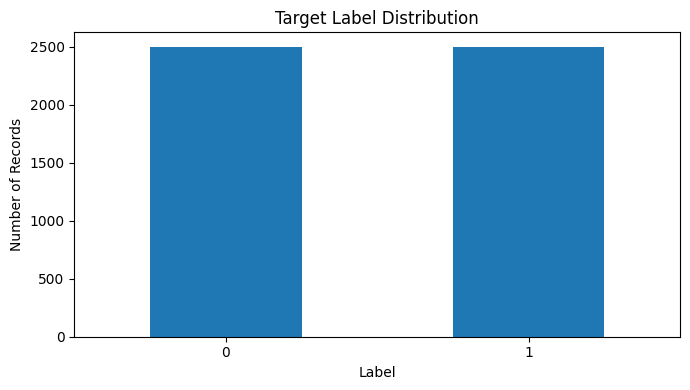


FEATURE STATISTICS BY LABEL


age                  bmi              blood_pressure                \
        mean median    std   mean median   std           mean median    std   
label                                                                         
0      47.50   46.0  14.52  27.63   27.5  5.27         120.06  120.0  16.23   
1      52.36   53.0  14.59  29.58   29.5  5.55         122.99  123.0  16.26   

      glucose               cholesterol               smoking               
         mean median    std        mean median    std    mean median   std  
label                                                                       
0      105.13  104.0  24.75      210.10  210.0  29.43    0.27    0.0  0.44  
1      128.44  128.0  27.90      216.33  216.0  30.12    0.30    0.0  0.46


FEATURE CORRELATION WITH LABEL


,Correlation with label
glucose,0.4043
bmi,0.1776
age,0.1647
cholesterol,0.1042
blood_pressure,0.0896
smoking,0.0293


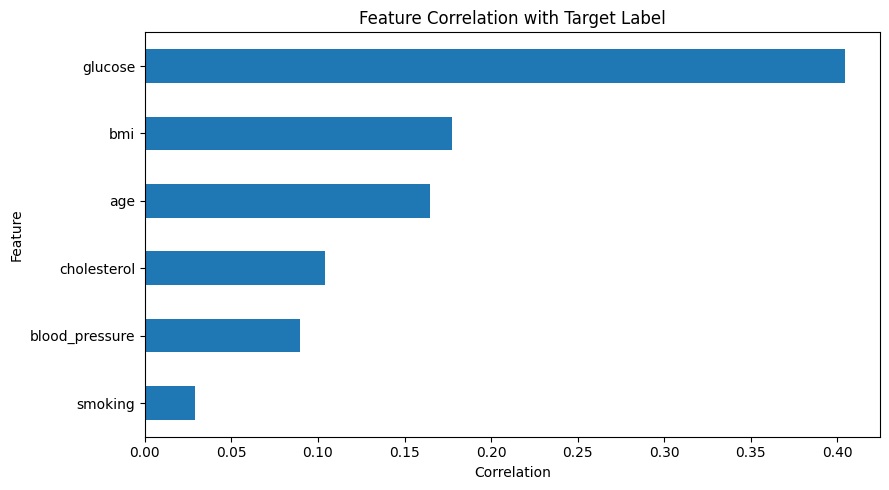

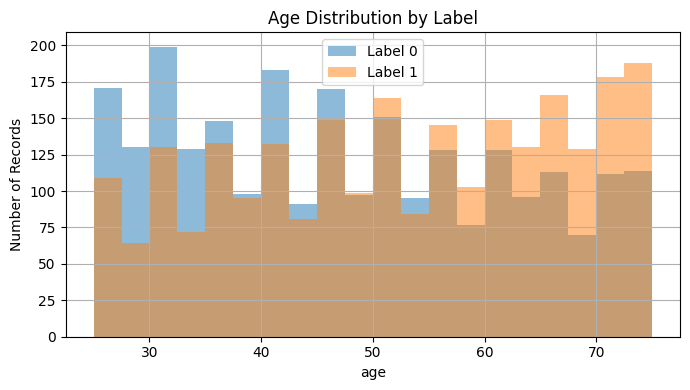

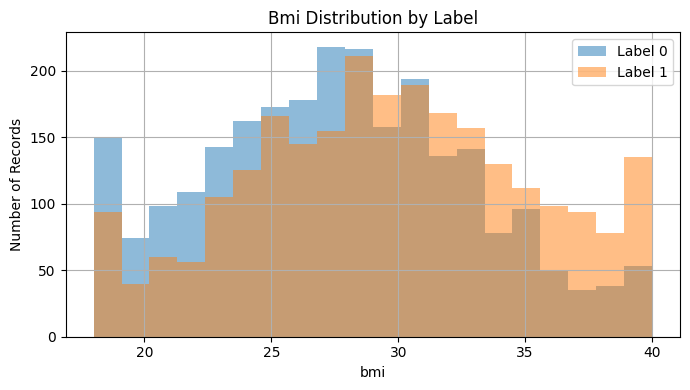

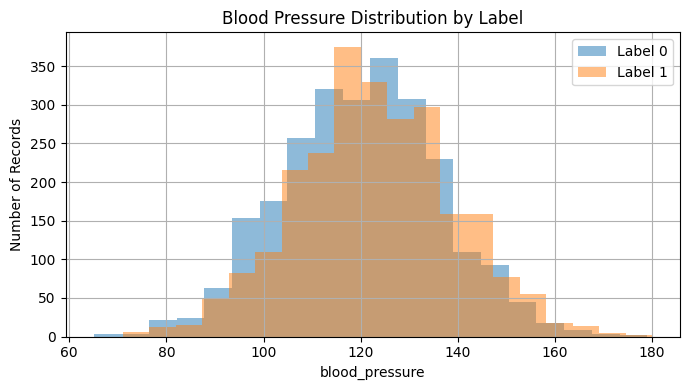

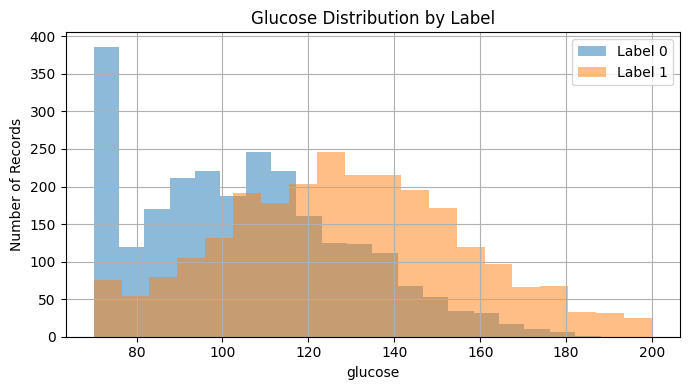

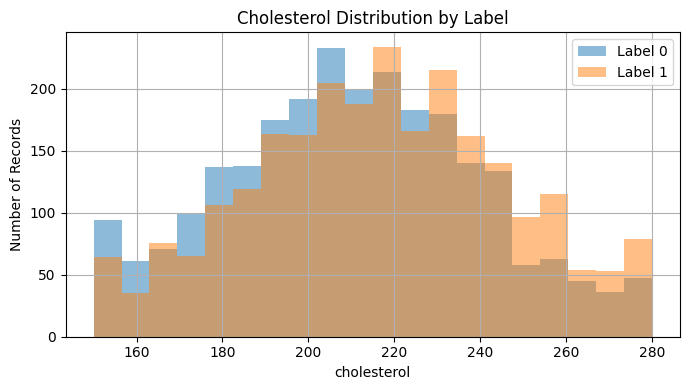

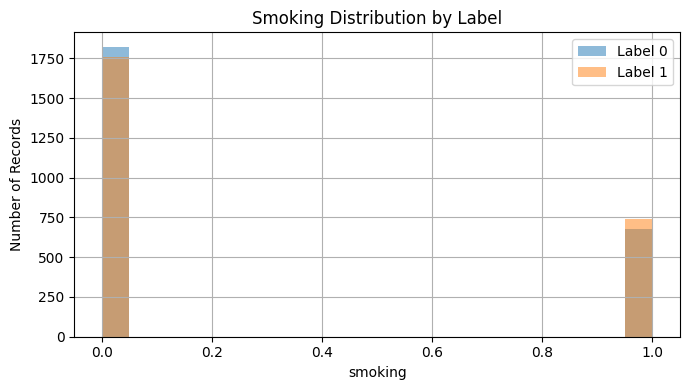


EDA COMPLETED
Important: correlations and patterns do not prove that the labels are medically correct.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_path / "data"

df = pd.read_csv(data_path / "dataset.csv")

print("DATASET OVERVIEW")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst five records:")
display(df.head())

print("\nDATA QUALITY")
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())

if "patient_id" in df.columns:
    print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())

print("\nNUMERICAL SUMMARY")
display(df.describe().round(2))

if "label" not in df.columns:
    raise ValueError("The dataset must contain a 'label' column.")

print("\nLABEL DISTRIBUTION")
label_counts = df["label"].value_counts().sort_index()
display(label_counts.to_frame("Count"))

display(
    (df["label"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .to_frame("Percentage")
)

plt.figure(figsize=(7, 4))
label_counts.plot(kind="bar")
plt.title("Target Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

numeric_df = df.select_dtypes(include=np.number)
feature_columns = [
    col for col in numeric_df.columns
    if col not in ["label"] and col != "patient_id"
]

print("\nFEATURE STATISTICS BY LABEL")
display(df.groupby("label")[feature_columns].agg(["mean", "median", "std"]).round(2))

print("\nFEATURE CORRELATION WITH LABEL")
correlations = numeric_df.corr(numeric_only=True)["label"].drop("label")
correlations = correlations.sort_values(key=abs, ascending=False)
display(correlations.to_frame("Correlation with label").round(4))

plt.figure(figsize=(9, 5))
correlations.sort_values().plot(kind="barh")
plt.title("Feature Correlation with Target Label")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

for column in feature_columns:
    plt.figure(figsize=(7, 4))

    for label in sorted(df["label"].dropna().unique()):
        df.loc[df["label"] == label, column].dropna().hist(
            bins=20,
            alpha=0.5,
            label=f"Label {label}"
        )

    plt.title(f"{column.replace('_', ' ').title()} Distribution by Label")
    plt.xlabel(column)
    plt.ylabel("Number of Records")
    plt.legend()
    plt.tight_layout()
    plt.show()

print("\nEDA COMPLETED")
print("Important: correlations and patterns do not prove that the labels are medically correct.")